# IX.1.3 — Parámetros de API y eliminación del determinismo

Este notebook reproduce la evidencia del punto **IX.1.3** sin llamar a APIs externas y sin modificar fuentes.

Objetivo:

1. separar lo solicitado por el código, lo registrado en los artefactos y lo enviado por la biblioteca;
2. documentar la ausencia de `reasoning_effort` y el valor desconocido del esfuerzo histórico;
3. dejar constancia de la ejecución única;
4. señalar las ubicaciones del manuscrito que deben revisarse.

> **Advertencia:** los logs de agentes no son volcados HTTP. No deben usarse como prueba de la temperatura aplicada.


In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

ART = Path.cwd()
if not (ART / "scripts" / "generar_evidencia.py").exists():
    candidates = [
        Path.cwd().parent / "analisis-valoracion-jurado" / "correccion-03-documentar-api-eliminar-determinismo",
        Path.cwd() / "analisis-valoracion-jurado" / "correccion-03-documentar-api-eliminar-determinismo",
    ]
    ART = next(path for path in candidates if (path / "scripts" / "generar_evidencia.py").exists())

sys.path.insert(0, str(ART))
from scripts.generar_evidencia import main

print("Carpeta de artefactos:", ART)


Carpeta de artefactos: /mnt/d/OneDrive/ex_dropbox/tesis-maestria-data-mining/analisis-valoracion-jurado/correccion-03-documentar-api-eliminar-determinismo


## 1. Generar la evidencia

La siguiente celda ejecuta el mismo script que produce `salidas/`. No usa red: la captura del payload se hace con `httpx.MockTransport`.


In [2]:
summary = main()
summary


1/8 Manifiesto de entradas...


2/8 Carga de respuestas primarias...
3/8 Captura local de payloads (sin red)...


4/8 Evidencia de Pydantic AI...
5/8 Evidencia de esfuerzo de razonamiento...


6/8 Tablas derivadas...


7/8 Figura...


8/8 Resumen...
Listo. Artefactos en: /mnt/d/OneDrive/ex_dropbox/tesis-maestria-data-mining/analisis-valoracion-jurado/correccion-03-documentar-api-eliminar-determinismo/salidas


{'fecha_ejecucion_utc': '2026-11-12T00:48:38.046612+00:00',
 'manifest': {'fecha_ejecucion_utc': '2026-11-12T00:48:21.994872+00:00',
  'archivos': 1880,
  'bytes': 66035421,
  'por_categoria': {'fuente_o_manuscrito': 15,
   'log_agente': 1838,
   'reporte_juez': 27},
  'sha256_conjunto': '18857449831a2cee0d559f4ed4c5464961488a3fd5c57327e2fb2151104a8e25',
  'nota': 'Los hashes se calculan antes de generar las tablas derivadas; no se modifica ninguna fuente.'},
 'pydantic_ai': {'version': '1.1.0',
  'perfiles': {'gpt-5-nano': {'tipo_perfil': 'OpenAIModelProfile',
    'openai_unsupported_model_settings': ['temperature',
     'top_p',
     'presence_penalty',
     'frequency_penalty',
     'logit_bias',
     'logprobs',
     'top_logprobs'],
    'temperatura_entre_no_admitidos': True},
   'gpt-5-mini': {'tipo_perfil': 'OpenAIModelProfile',
    'openai_unsupported_model_settings': ['temperature',
     'top_p',
     'presence_penalty',
     'frequency_penalty',
     'logit_bias',
     'logpr

## 2. Configuración solicitada, registrada y perfil de la biblioteca

`temperatura_en_payload=False` significa que el cuerpo construido por Pydantic AI no contiene `temperature`. `settings_registrados_log` muestra lo que quedó en el metadata de la aplicación, que no es el cuerpo HTTP.


In [3]:
config = pd.read_csv(ART / "salidas" / "tabla_configuracion_solicitado_registrado_efectivo.csv")
display(
    config[
        [
            "estrategia",
            "componente",
            "modelo_rol",
            "modelo_especialista",
            "settings_solicitados_codigo",
            "settings_registrados_log",
            "temperatura_en_payload",
            "reasoning_effort_solicitado",
            "reasoning_effort_registrado",
            "respuestas_blancas",
        ]
    ]
)


,estrategia,componente,modelo_rol,modelo_especialista,settings_solicitados_codigo,settings_registrados_log,temperatura_en_payload,reasoning_effort_solicitado,reasoning_effort_registrado,respuestas_blancas
0,sin_rag,especialista,gpt-5-nano,gpt-5-nano,"{""temperature"":0.0}","{""temperature"":0.0} (79)",False,False,False,0
1,sin_rag,especialista,gpt-5-mini,gpt-5-mini,"{""temperature"":0.0}","{""temperature"":0.0} (79)",False,False,False,0
2,sin_rag,especialista,gpt-5,gpt-5,"{""temperature"":0.0}","{""temperature"":0.0} (79)",False,False,False,0
3,rag_basico,especialista,gpt-5-nano,gpt-5-nano,"{""temperature"":0.0}","{""temperature"":0.0} (79)",False,False,False,0
4,rag_basico,especialista,gpt-5-mini,gpt-5-mini,"{""temperature"":0.0}","{""temperature"":0.0} (79)",False,False,False,0
5,rag_basico,especialista,gpt-5,gpt-5,"{""temperature"":0.0}","{""temperature"":0.0} (79)",False,False,False,0
6,agentic_rag,especialista,gpt-5-nano,gpt-5-nano,"{""temperature"":0.0}",{} (79),False,False,False,28
7,agentic_rag,recuperador,gpt-5,gpt-5-nano,"{""temperature"":0.0}",{} (79),False,False,False,N/A (agente de recuperación)
8,agentic_rag,especialista,gpt-5-mini,gpt-5-mini,"{""temperature"":0.0}",{} (79),False,False,False,0
9,agentic_rag,recuperador,gpt-5,gpt-5-mini,"{""temperature"":0.0}",{} (79),False,False,False,N/A (agente de recuperación)


## 3. Tokens de razonamiento y ejecución única

Los tokens de razonamiento están presentes, pero no identifican el esfuerzo solicitado ni el aplicado. La tabla de ejecuciones muestra 79 registros para 79 unidades en cada celda y ningún campo de réplica.


In [4]:
reasoning = pd.read_csv(ART / "salidas" / "tabla_reasoning_tokens_por_celda.csv")
display(reasoning)
execution = pd.read_csv(ART / "salidas" / "tabla_ejecuciones_unicas.csv")
display(
    execution[
        [
            "estrategia",
            "modelo",
            "registros",
            "unidades_unicas",
            "duplicados_unidad",
            "replicas_identificadas",
            "campo_run_id_replica",
            "respuestas_blancas",
        ]
    ]
)


,estrategia,componente,modelo_rol,n,min,p25,mediana,p75,max,media,total,output_tokens_mediana,proporcion_razonamiento_mediana,respuestas_blancas,fuente
0,sin_rag,especialista,gpt-5-nano,79,2432.0,4800.0,5376.0,6272.0,8512.0,5521.8228,436224.0,6080.0,0.9096,0.0,codigo_experimentos/part_h/llm_responses_all_r...
1,sin_rag,especialista,gpt-5-mini,79,704.0,1152.0,1408.0,1888.0,2944.0,1539.2405,121600.0,1999.0,0.7582,0.0,codigo_experimentos/part_h/llm_responses_all_r...
2,sin_rag,especialista,gpt-5,79,2048.0,3296.0,4096.0,4672.0,6016.0,4089.5190,323072.0,4770.0,0.8856,0.0,codigo_experimentos/part_h/llm_responses_all_r...
3,rag_basico,especialista,gpt-5-nano,79,1344.0,3808.0,4864.0,6464.0,10816.0,5184.8101,409600.0,5603.0,0.8977,0.0,codigo_experimentos/part_h/llm_responses_all_r...
4,rag_basico,especialista,gpt-5-mini,79,640.0,1280.0,1536.0,1984.0,3648.0,1623.4937,128256.0,2212.0,0.6990,0.0,codigo_experimentos/part_h/llm_responses_all_r...
5,rag_basico,especialista,gpt-5,79,768.0,2208.0,3072.0,3808.0,5888.0,2987.7468,236032.0,3377.0,0.8821,0.0,codigo_experimentos/part_h/llm_responses_all_r...
6,agentic_rag,especialista,gpt-5-nano,79,512.0,2464.0,3456.0,4928.0,8448.0,3729.0127,294592.0,3949.0,0.9143,28.0,codigo_experimentos/part_h/llm_responses_all_r...
7,agentic_rag,recuperador,gpt-5,79,1536.0,3840.0,4608.0,5568.0,10816.0,4807.2911,379776.0,6297.0,0.7823,NaN,codigo_experimentos/part_h/llm_responses_all_r...
8,agentic_rag,especialista,gpt-5-mini,79,448.0,1120.0,1344.0,1728.0,3392.0,1433.9241,113280.0,2399.0,0.6087,0.0,codigo_experimentos/part_h/llm_responses_all_r...
9,agentic_rag,recuperador,gpt-5,79,2304.0,3968.0,4800.0,6016.0,9600.0,5037.3671,397952.0,6879.0,0.7366,NaN,codigo_experimentos/part_h/llm_responses_all_r...


,estrategia,modelo,registros,unidades_unicas,duplicados_unidad,replicas_identificadas,campo_run_id_replica,respuestas_blancas
0,sin_rag,gpt-5-nano,79,79,0,0,no existe en el artefacto,0
1,sin_rag,gpt-5-mini,79,79,0,0,no existe en el artefacto,0
2,sin_rag,gpt-5,79,79,0,0,no existe en el artefacto,0
3,rag_basico,gpt-5-nano,79,79,0,0,no existe en el artefacto,0
4,rag_basico,gpt-5-mini,79,79,0,0,no existe en el artefacto,0
5,rag_basico,gpt-5,79,79,0,0,no existe en el artefacto,0
6,agentic_rag,gpt-5-nano,79,79,0,0,no existe en el artefacto,28
7,agentic_rag,gpt-5-mini,79,79,0,0,no existe en el artefacto,0
8,agentic_rag,gpt-5,79,79,0,0,no existe en el artefacto,0


## 4. Captura local del payload

Se capturaron 12 cuerpos de petición: sin RAG, RAG básico, especialista agéntico y recuperador agéntico para los tres modelos. Ninguno contiene `temperature` ni `reasoning_effort`.


In [5]:
import json

payloads = json.loads((ART / "salidas" / "evidencia_payloads_locales.json").read_text(encoding="utf-8"))
payload_rows = []
for call in payloads["calls"]:
    payload_rows.append(
        {
            "clave": call["clave"],
            "claves_del_cuerpo": ", ".join(call["request_body_keys"]),
            "temperature_presente": call["temperature_presente"],
            "reasoning_effort_presente": call["reasoning_effort_presente"],
            "max_completion_tokens_presente": call["max_completion_tokens_presente"],
            "settings_solicitados": call["model_settings_solicitados"],
        }
    )
display(pd.DataFrame(payload_rows))


,clave,claves_del_cuerpo,temperature_presente,reasoning_effort_presente,max_completion_tokens_presente,settings_solicitados
0,sin_rag|especialista|gpt-5-nano,"messages, model, stream",False,False,False,{'temperature': 0.0}
1,rag_basico|especialista|gpt-5-nano,"messages, model, stream",False,False,False,{'temperature': 0.0}
2,agentic_rag|especialista|gpt-5-nano,"messages, model, stream, tool_choice, tools",False,False,False,{'temperature': 0.0}
3,agentic_rag|recuperador|gpt-5,"messages, model, stream, tool_choice, tools",False,False,False,{'temperature': 0.0}
4,sin_rag|especialista|gpt-5-mini,"messages, model, stream",False,False,False,{'temperature': 0.0}
5,rag_basico|especialista|gpt-5-mini,"messages, model, stream",False,False,False,{'temperature': 0.0}
6,agentic_rag|especialista|gpt-5-mini,"messages, model, stream, tool_choice, tools",False,False,False,{'temperature': 0.0}
7,agentic_rag|recuperador|gpt-5,"messages, model, stream, tool_choice, tools",False,False,False,{'temperature': 0.0}
8,sin_rag|especialista|gpt-5,"messages, model, stream",False,False,False,{'temperature': 0.0}
9,rag_basico|especialista|gpt-5,"messages, model, stream",False,False,False,{'temperature': 0.0}


## 5. Perfil de Pydantic AI

Los tres perfiles declaran `temperature` entre los parámetros no admitidos. El extracto fuente muestra el `pop` que elimina esos settings antes de construir la solicitud.


In [6]:
pydantic_evidence = json.loads(
    (ART / "salidas" / "evidencia_perfil_pydantic.json").read_text(encoding="utf-8")
)
profile_rows = []
for model, profile in pydantic_evidence["perfiles"].items():
    profile_rows.append(
        {
            "modelo": model,
            "temperatura_no_admitida": profile["temperatura_entre_no_admitidos"],
            "settings_no_admitidos": ", ".join(profile["openai_unsupported_model_settings"]),
        }
    )
display(pd.DataFrame(profile_rows))
print((ART / "salidas" / "evidencia_pydantic_ai_excerpt.txt").read_text(encoding="utf-8"))


,modelo,temperatura_no_admitida,settings_no_admitidos
0,gpt-5,True,"temperature, top_p, presence_penalty, frequenc..."
1,gpt-5-mini,True,"temperature, top_p, presence_penalty, frequenc..."
2,gpt-5-nano,True,"temperature, top_p, presence_penalty, frequenc..."


Archivo: /mnt/d/OneDrive/ex_dropbox/tesis-maestria-data-mining/codigo_experimentos/.venv/lib/python3.13/site-packages/pydantic_ai/models/openai.py
Función: OpenAIChatModel._completions_create, desde línea 448
SHA-256 del archivo: 9c2a85cb6b118a1ca06c16d36126cccbf5bd2e25f036847321434748993972d7
Líneas del archivo: 477 a 493

        ):  # pragma: no branch
            response_format = {'type': 'json_object'}

        unsupported_model_settings = OpenAIModelProfile.from_profile(self.profile).openai_unsupported_model_settings
        for setting in unsupported_model_settings:
            model_settings.pop(setting, None)

        try:
            extra_headers = model_settings.get('extra_headers', {})
            extra_headers.setdefault('User-Agent', get_user_agent())
            return await self.client.chat.completions.create(
                model=self._model_name,
                messages=openai_messages,
                parallel_tool_calls=model_settings.get('parallel_tool_calls', 

## 6. Ubicaciones del texto que deben revisarse

Esta tabla es la entrada para la edición posterior. No se modifica ningún `.typ` desde este notebook.


In [7]:
claims = pd.read_csv(ART / "salidas" / "tabla_ubicaciones_texto_a_modificar.csv")
display(
    claims[
        [
            "archivo",
            "linea",
            "alcance",
            "prioridad",
            "texto_actual_coincidente",
            "texto_propuesto",
        ]
    ]
)


,archivo,linea,alcance,prioridad,texto_actual_coincidente,texto_propuesto
0,manuscrito/capitulos/06_capitulo_05_metodologi...,196,oración completa,obligatoria,Se emplea la misma configuración de agente (Py...,Se emplea la misma configuración de agente (Py...
1,manuscrito/capitulos/06_capitulo_05_metodologi...,461,oración completa,obligatoria,La temperatura controla la aleatoriedad de las...,La temperatura es un parámetro de muestreo. En...
2,manuscrito/capitulos/06_capitulo_05_metodologi...,471,fila completa de tabla,obligatoria,| Temperatura | ...,"| Temperatura solicitada en el código | 0,0#su..."
3,manuscrito/capitulos/06_capitulo_05_metodologi...,495,línea completa (eliminar),obligatoria,+ Soporte para generación con temperatura cero...,[Eliminar el ítem. Si se desea conservar una n...
4,manuscrito/capitulos/06_capitulo_05_metodologi...,505,oración completa,obligatoria,Todos los modelos fueron configurados con temp...,Los tres modelos pertenecen a la familia GPT-5...
5,manuscrito/capitulos/06_capitulo_05_metodologi...,644,línea completa,obligatoria,+ Temperatura 0 para respuestas determinística...,+ Una única ejecución por unidad y configuraci...
6,manuscrito/capitulos/06_capitulo_05_metodologi...,598,oración completa,obligatoria,Los tres modelos fueron configurados con tempe...,Los tres modelos jueces se configuraron en Ope...
7,manuscrito/capitulos/07_capitulo_06_evaluacion...,16,oración completa,obligatoria,El diseño experimental sigue un esquema factor...,El diseño experimental sigue un esquema factor...
8,codigo_experimentos/performed_tasks_summary.md,66,fragmento de la descripción de la tabla,obligatoria,Uses Pydantic AI agents with temperature=0 for...,Uses Pydantic AI agents; the code requested `t...
9,manuscrito/capitulos/06_capitulo_05_metodologi...,8,oración completa,recomendada,La implementación se organizó en módulos indep...,La implementación se organizó en módulos indep...


## 7. Figura de apoyo

La figura muestra la mediana de tokens de razonamiento por celda. Es una descripción del consumo, no una medida del esfuerzo.


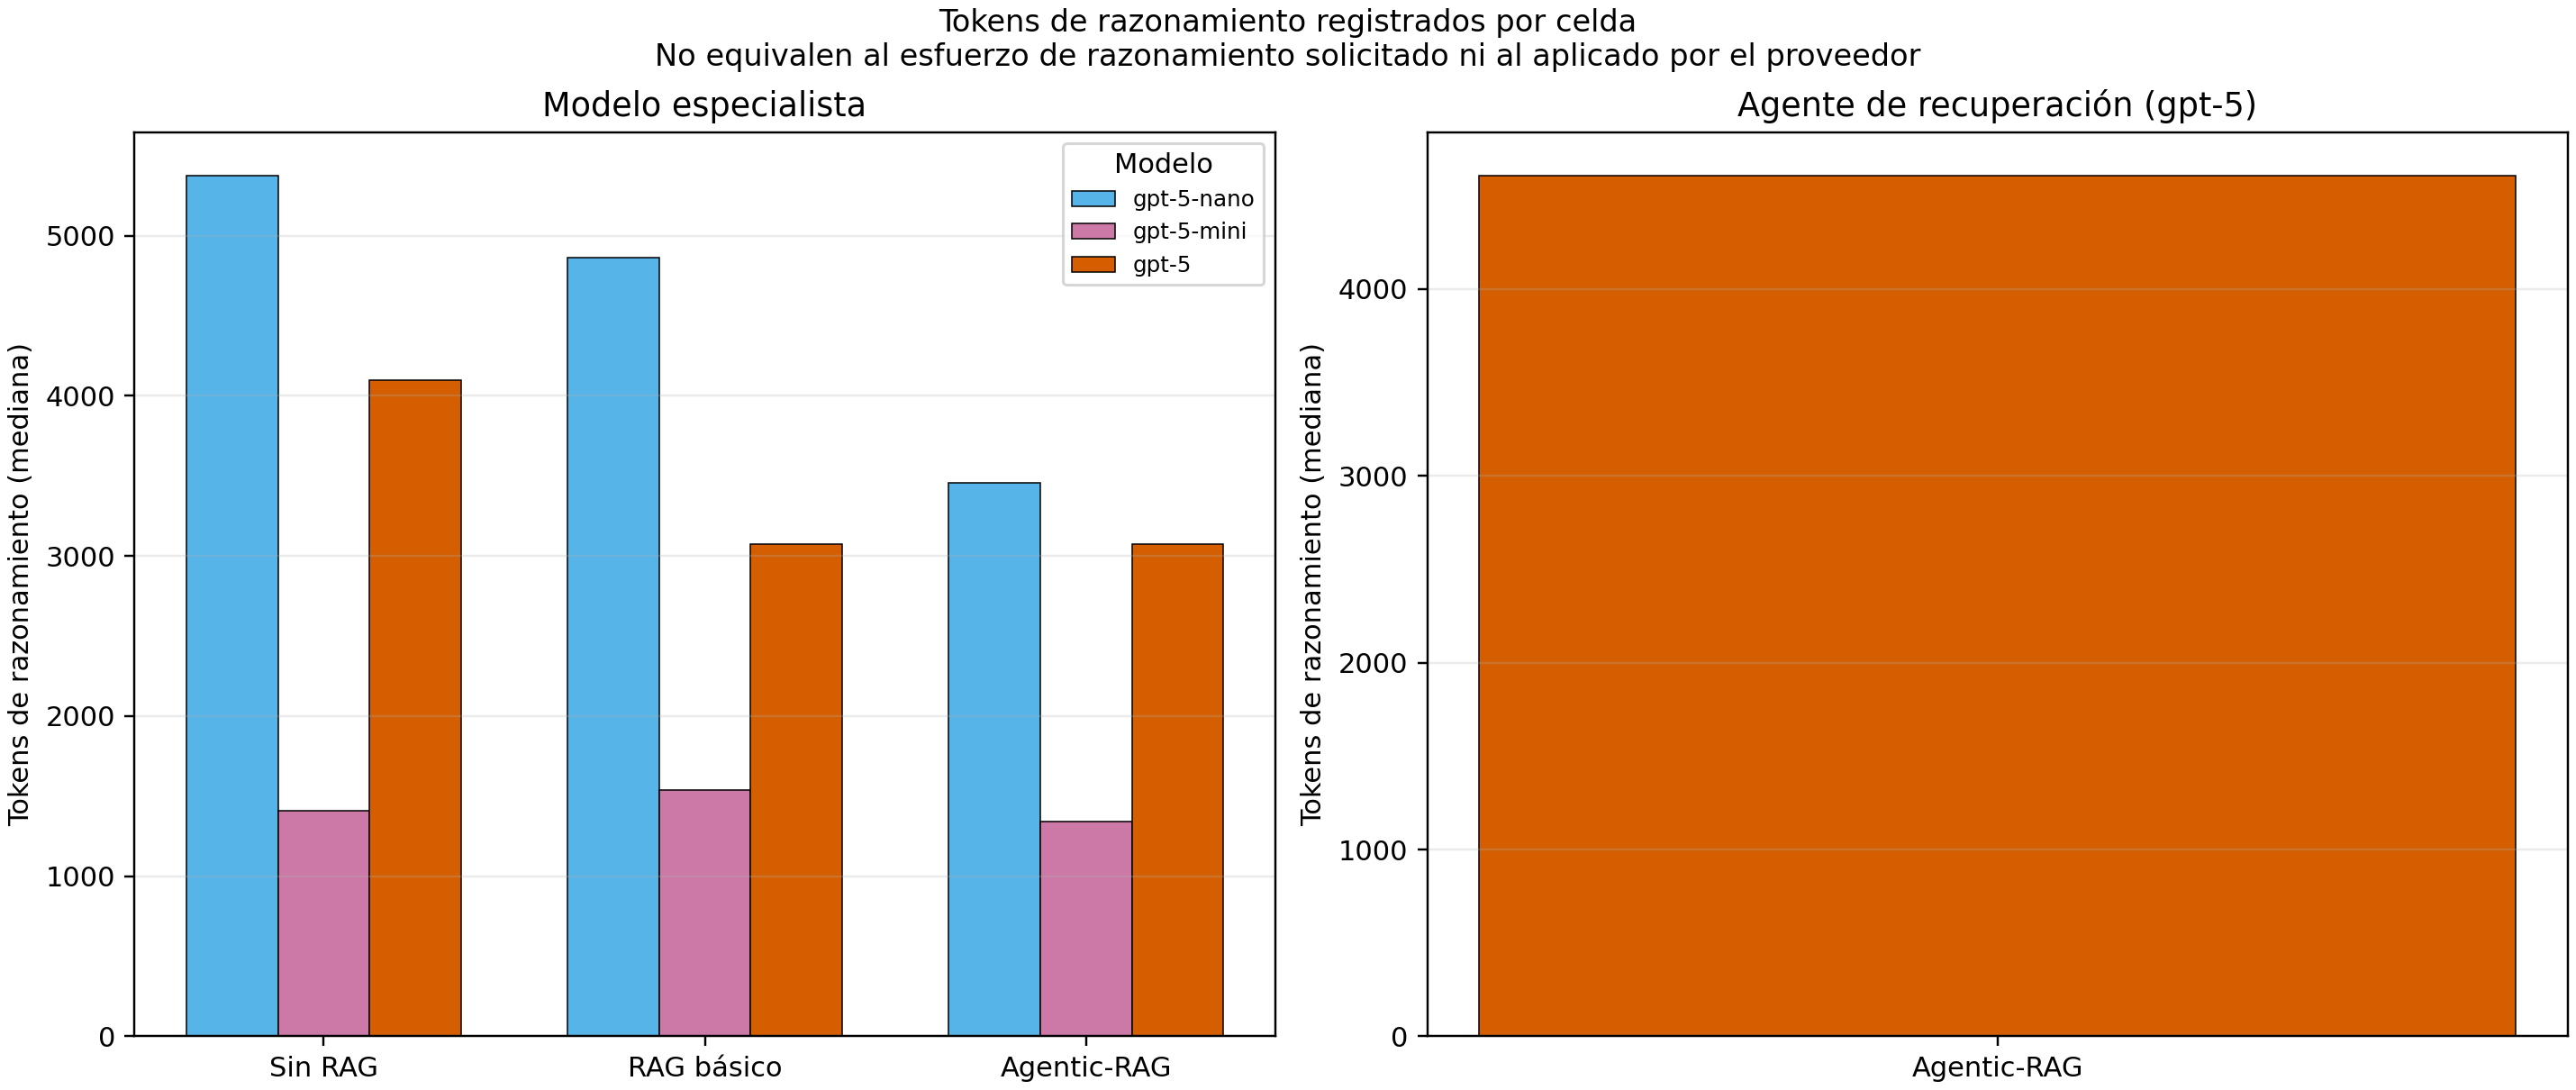

In [8]:
display(Image(filename=str(ART / "salidas" / "fig_tokens_razonamiento_por_celda.png")))


## 8. Lectura de resultados

- La temperatura fue solicitada en el código, pero no está en el payload de los modelos GPT-5.
- Los logs de sin RAG/RAG básico conservan `temperature=0.0`; los de Agentic-RAG guardan `{}`. El log no es el payload.
- No hay `reasoning_effort` en el código de generación ni en los logs revisados; el esfuerzo histórico es desconocido.
- Las 711 respuestas tienen `reasoning_tokens`, pero esos tokens no permiten reconstruir el esfuerzo.
- Hay 79 registros por celda para 79 unidades y ningún campo de réplica: la ejecución única debe declararse como limitación.
- Los jueces tienen su propia configuración en OpenRouter y no se usan para afirmar determinismo de los generadores.

Las propuestas concretas de redacción están en `propuestas_edicion.md` y en `salidas/tabla_ubicaciones_texto_a_modificar.csv`.
